# PSD Computation and Analysis Basics in Python

This notebook teaches the basics of **power spectral density (PSD)** computation and interpretation.

It is written for someone who is new to spectral analysis, especially for signals like EEG.

By the end, you should understand:
- what a PSD is
- why PSD is useful
- how to compute a PSD in Python
- how choices like window length affect the result
- how to extract simple band-power summaries


## 1. What is a PSD?

A **power spectral density** shows how the power of a signal is distributed across frequencies.

Instead of asking:
- how does the signal change over time?

a PSD asks:
- how much of the signal's energy is present at different frequencies?

For example, if a signal contains a strong 10 Hz rhythm, the PSD should show a peak near **10 Hz**.

This is especially useful for signals like EEG, where we often care about rhythms in certain frequency bands.

## 2. Imports


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal


## 3. Build a simple signal

Let's make a toy signal with:
- a 10 Hz oscillation
- a 25 Hz oscillation
- random noise

This helps us see whether the PSD can recover the frequencies we already know are present.

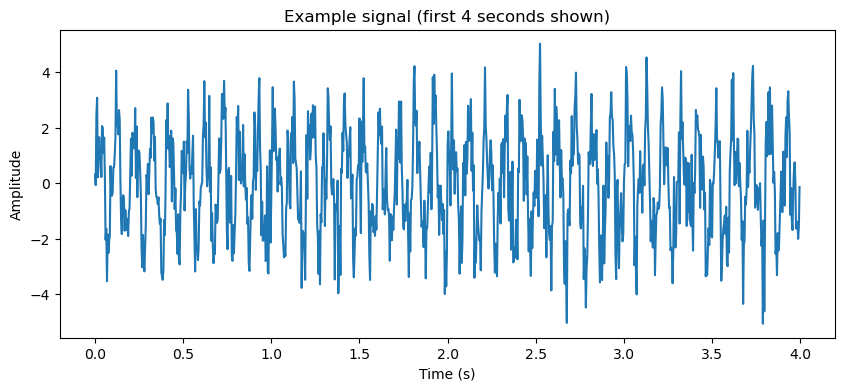

In [2]:
fs = 250  # sampling frequency in Hz
duration = 10  # seconds
t = np.arange(0, duration, 1/fs)

rng = np.random.default_rng(42)

sig_10hz = 2.0 * np.sin(2 * np.pi * 10 * t)
sig_25hz = 0.8 * np.sin(2 * np.pi * 25 * t)
noise = 1.0 * rng.normal(size=len(t))

x = sig_10hz + sig_25hz + noise

plt.figure(figsize=(10, 4))
plt.plot(t[:1000], x[:1000])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Example signal (first 4 seconds shown)')
plt.show()

## 4. Compute a PSD with Welch's method

A common way to estimate PSD is **Welch's method**.

Why Welch?
- It is more stable than using a single FFT of the whole signal.
- It splits the signal into overlapping windows.
- It computes a spectrum for each window.
- Then it averages them.

This usually gives a smoother, more reliable PSD estimate.

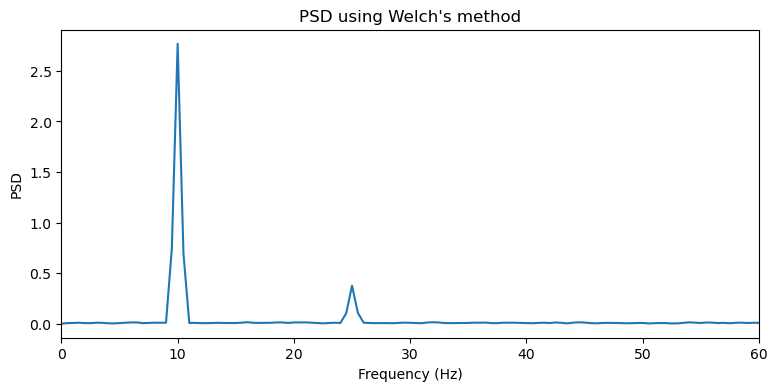

In [3]:
freqs, psd = signal.welch(
    x,
    fs=fs,
    nperseg=500,      # 2-second windows at 250 Hz
    noverlap=250,    # 50% overlap
    scaling='density'
)

plt.figure(figsize=(9, 4))
plt.plot(freqs, psd)
plt.xlim(0, 60)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title("PSD using Welch's method")
plt.show()

## 5. Plotting on a log scale

PSD values often span a wide range, so it is common to inspect them on a log scale.

For biological signals like EEG, this often makes the shape easier to interpret.

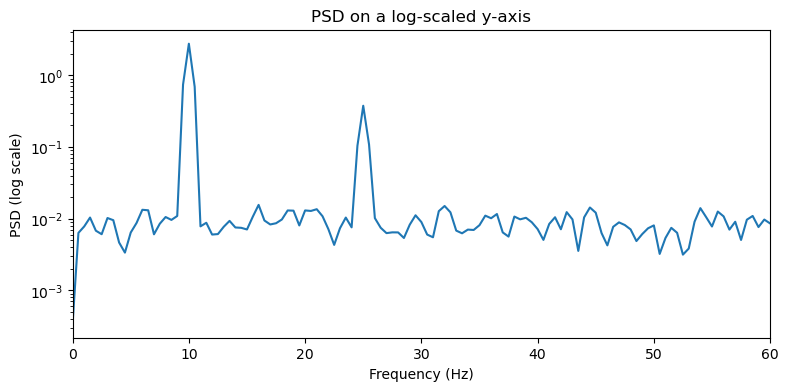

In [4]:
plt.figure(figsize=(9, 4))
plt.semilogy(freqs, psd)
plt.xlim(0, 60)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (log scale)')
plt.title('PSD on a log-scaled y-axis')
plt.show()

## 6. Interpreting the PSD

You should see peaks near:
- **10 Hz**
- **25 Hz**

That is exactly what we built into the signal.

The noisy background reflects broadband activity from the random noise.

In real EEG, PSDs often contain:
- peaks from oscillations
- broadband background structure
- line noise peaks such as 50 or 60 Hz


## 7. Why window length matters

One important Welch parameter is `nperseg`, the number of samples per window.

There is a tradeoff:
- **Longer windows** -> better frequency resolution, but fewer averages
- **Shorter windows** -> smoother estimate, but poorer frequency resolution

Let's compare a few choices.

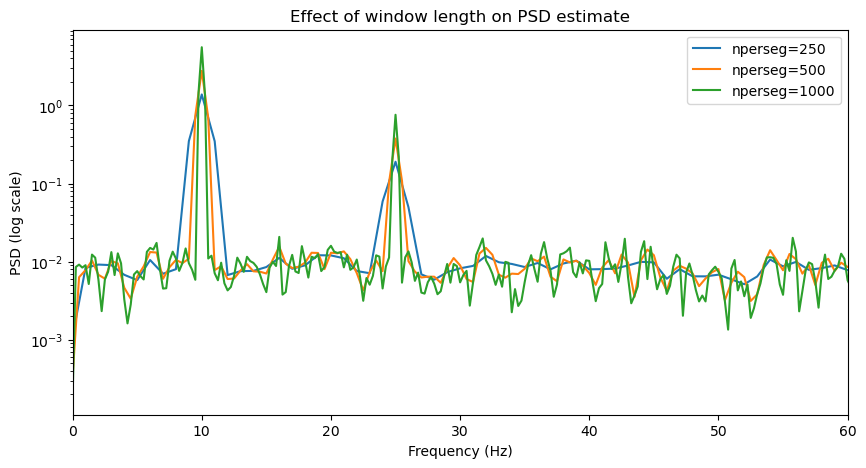

In [5]:
window_lengths = [250, 500, 1000]  # 1 s, 2 s, 4 s at fs=250

plt.figure(figsize=(10, 5))
for nperseg in window_lengths:
    f, p = signal.welch(x, fs=fs, nperseg=nperseg, noverlap=nperseg//2)
    plt.semilogy(f, p, label=f'nperseg={nperseg}')

plt.xlim(0, 60)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (log scale)')
plt.title('Effect of window length on PSD estimate')
plt.legend()
plt.show()

## 8. Frequency resolution intuition

A useful rough rule is:

`frequency resolution ~= fs / nperseg`

So if:
- `fs = 250 Hz`
- `nperseg = 500`

then the spacing between neighboring frequency bins is about:

`250 / 500 = 0.5 Hz`


In [6]:
for nperseg in [250, 500, 1000]:
    resolution = fs / nperseg
    print(f'nperseg={nperseg}: frequency resolution ~ {resolution:.3f} Hz')

nperseg=250: frequency resolution ~ 1.000 Hz
nperseg=500: frequency resolution ~ 0.500 Hz
nperseg=1000: frequency resolution ~ 0.250 Hz


## 9. Compare time-domain and frequency-domain views

The same signal can look messy in time, but its PSD can reveal the underlying oscillatory structure.

That is one of the main reasons PSD analysis is so useful.

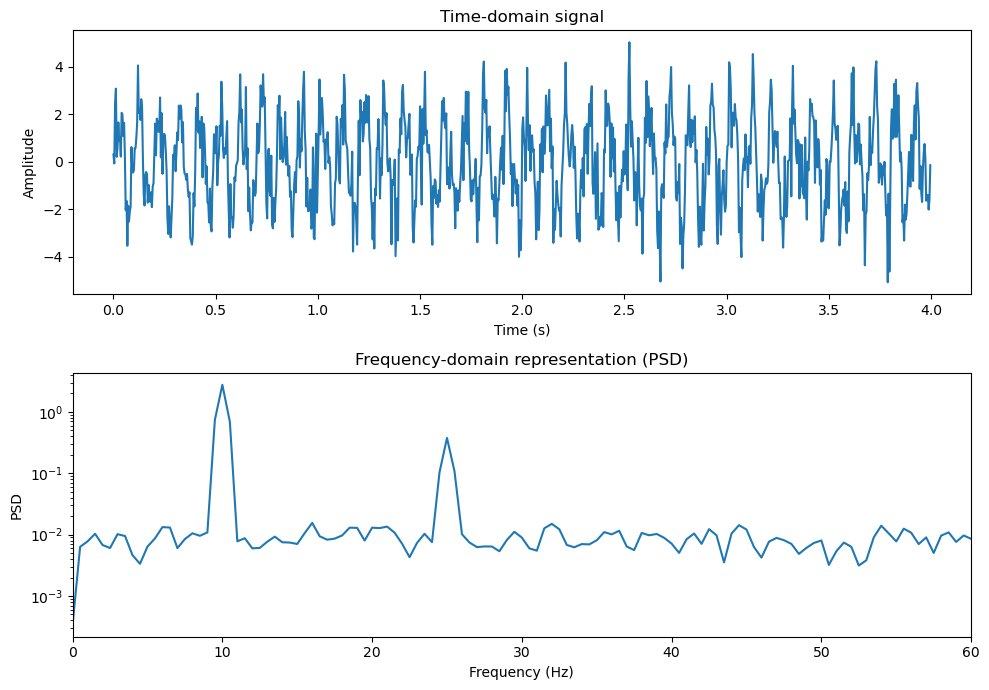

In [7]:
fig = plt.figure(figsize=(10, 7))

ax1 = fig.add_subplot(2, 1, 1)
ax1.plot(t[:1000], x[:1000])
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.set_title('Time-domain signal')

ax2 = fig.add_subplot(2, 1, 2)
ax2.semilogy(freqs, psd)
ax2.set_xlim(0, 60)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('PSD')
ax2.set_title('Frequency-domain representation (PSD)')

plt.tight_layout()
plt.show()

## 10. Band power

A very common PSD summary is **band power**.

This means integrating PSD values across a frequency band of interest.

For example:
- delta: 1-4 Hz
- theta: 4-8 Hz
- alpha: 8-12 Hz
- beta: 12-30 Hz

The exact band definitions depend on the field and the species.

In [8]:
def bandpower(freqs, psd, fmin, fmax):
    mask = (freqs >= fmin) & (freqs <= fmax)
    return np.trapz(psd[mask], freqs[mask])

bands = {
    'delta (1-4 Hz)': (1, 4),
    'theta (4-8 Hz)': (4, 8),
    'alpha (8-12 Hz)': (8, 12),
    'beta (12-30 Hz)': (12, 30),
}

for name, (fmin, fmax) in bands.items():
    bp = bandpower(freqs, psd, fmin, fmax)
    print(f'{name}: {bp:.4f}')

delta (1-4 Hz): 0.0245
theta (4-8 Hz): 0.0334
alpha (8-12 Hz): 2.1258
beta (12-30 Hz): 0.4429


## 11. Visualize the band boundaries

This makes it easier to connect the numeric band-power values to the PSD itself.

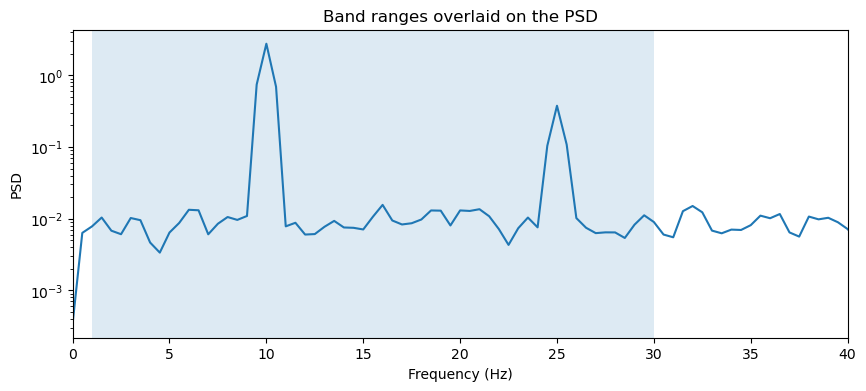

In [9]:
plt.figure(figsize=(10, 4))
plt.semilogy(freqs, psd)

for name, (fmin, fmax) in bands.items():
    plt.axvspan(fmin, fmax, alpha=0.15)

plt.xlim(0, 40)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Band ranges overlaid on the PSD')
plt.show()

## 12. Absolute vs relative band power

Two common summaries are:

### Absolute band power
- raw integrated power within a band

### Relative band power
- band power divided by total power across a larger reference range

Relative power can be useful when you want to compare the proportion of power in a band rather than raw magnitude.

In [10]:
total_power = bandpower(freqs, psd, 1, 40)

for name, (fmin, fmax) in bands.items():
    abs_bp = bandpower(freqs, psd, fmin, fmax)
    rel_bp = abs_bp / total_power
    print(f'{name}: absolute={abs_bp:.4f}, relative={rel_bp:.3f}')

delta (1-4 Hz): absolute=0.0245, relative=0.009
theta (4-8 Hz): absolute=0.0334, relative=0.012
alpha (8-12 Hz): absolute=2.1258, relative=0.783
beta (12-30 Hz): absolute=0.4429, relative=0.163


## 13. Example: adding line noise

Real recordings often have line noise near **60 Hz** (or 50 Hz in some places).

Let's add a 60 Hz sinusoid and see how it appears in the PSD.

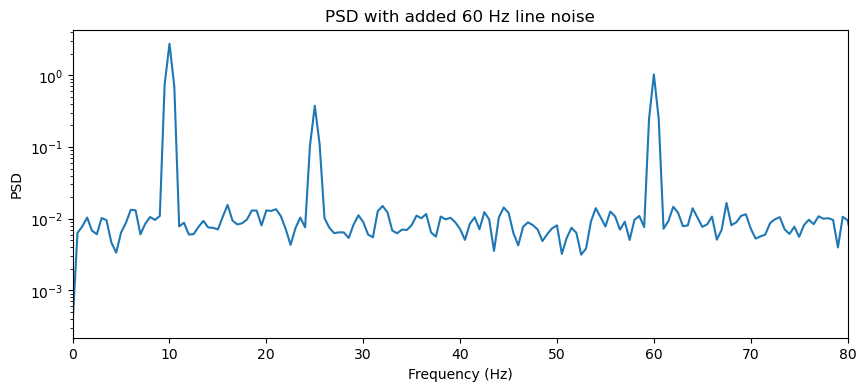

In [11]:
x_line = x + 1.2 * np.sin(2 * np.pi * 60 * t)
f_line, p_line = signal.welch(x_line, fs=fs, nperseg=500, noverlap=250)

plt.figure(figsize=(10, 4))
plt.semilogy(f_line, p_line)
plt.xlim(0, 80)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('PSD with added 60 Hz line noise')
plt.show()

## 14. Example: compare two signals

A common analysis question is whether one condition has more power in a certain band than another.

Let's create a second signal with stronger 25 Hz activity and compare the PSDs.

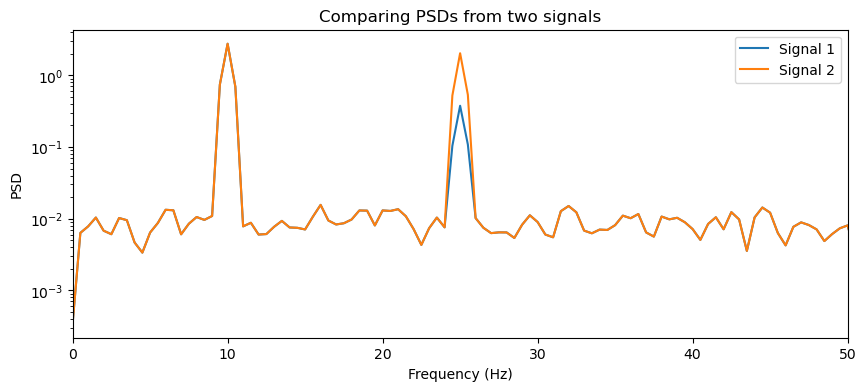

In [12]:
x2 = sig_10hz + 1.8 * np.sin(2 * np.pi * 25 * t) + noise

f1, p1 = signal.welch(x, fs=fs, nperseg=500, noverlap=250)
f2, p2 = signal.welch(x2, fs=fs, nperseg=500, noverlap=250)

plt.figure(figsize=(10, 4))
plt.semilogy(f1, p1, label='Signal 1')
plt.semilogy(f2, p2, label='Signal 2')
plt.xlim(0, 50)
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('Comparing PSDs from two signals')
plt.legend()
plt.show()

## 15. Quantify the difference with band power

Plotting is useful, but often we also want a simple numeric summary.

In [13]:
beta1 = bandpower(f1, p1, 12, 30)
beta2 = bandpower(f2, p2, 12, 30)

print(f'Signal 1 beta power (12-30 Hz): {beta1:.4f}')
print(f'Signal 2 beta power (12-30 Hz): {beta2:.4f}')
print(f'Difference: {beta2 - beta1:.4f}')

Signal 1 beta power (12-30 Hz): 0.4429
Signal 2 beta power (12-30 Hz): 1.6979
Difference: 1.2549


## 16. Common practical issues in PSD analysis

When working with real data, watch out for:

1. **Artifacts**
   - movement, saturations, electrode pops

2. **Line noise**
   - often around 50 or 60 Hz and harmonics

3. **Sampling rate limits**
   - the Nyquist frequency is `fs / 2`

4. **Window choices**
   - PSD estimates change with `nperseg`, overlap, and preprocessing

5. **Normalization choices**
   - absolute PSD, relative power, log power, or z-scored spectra can tell different stories


## 17. A helper function for repeated PSD computation

It is often useful to wrap your PSD settings into a reusable function.

In [14]:
def compute_psd(x, fs, nperseg=500, noverlap=None):
    if noverlap is None:
        noverlap = nperseg // 2
    freqs, psd = signal.welch(
        x,
        fs=fs,
        nperseg=nperseg,
        noverlap=noverlap,
        scaling='density'
    )
    return freqs, psd

freqs_demo, psd_demo = compute_psd(x, fs)
print(freqs_demo[:5])
print(psd_demo[:5])

[0.  0.5 1.  1.5 2. ]
[0.00034058 0.00631973 0.00778278 0.01035015 0.00678248]


## 18. A small exercise section

Try changing these things and rerunning the notebook:

1. Change the 10 Hz oscillation to 8 Hz.
2. Increase the noise level.
3. Change `nperseg` from 500 to 250 or 1000.
4. Add a 40 Hz oscillation.
5. Compute band power for a custom band like 30-50 Hz.

Questions to think about:
- Which changes are obvious in the PSD?
- Which changes become harder to detect as noise increases?
- How does window length change the sharpness of peaks?


## 19. Key takeaways

- A PSD tells you how signal power is distributed across frequency.
- Welch's method is a common, practical way to estimate PSD.
- Peaks in the PSD often reflect oscillations in the signal.
- Window length affects the tradeoff between smoothness and frequency resolution.
- Band power is a simple and common way to summarize PSD results.
- Real data analysis depends heavily on preprocessing and artifact handling.


## 20. Where to go next

Once these basics make sense, useful next topics include:
- spectrograms / STFT for time-varying frequency content
- multitaper spectral estimation
- normalization and log transforms
- comparing PSDs across groups or states
- parameterizing spectra into aperiodic and oscillatory components

For EEG work, PSD analysis is often just the start of a larger spectral analysis pipeline.